# WPBC: censoring and the choice of estimand

The clinical question is which patients are at high risk of breast-cancer
recurrence, used to set follow-up intensity. The direct approach is a
classifier: label each patient by whether recurrence was recorded, fit a model
to the tumour measurements, and read off a probability.

The recorded recurrence label depends on both the patient's disease course and
how long recurrence could be observed. Using the Wisconsin Prognostic Breast
Cancer data, we compare this binary target with a time-to-recurrence model that
uses censored follow-up as a lower bound on recurrence time.

The response definition changes the analysis: a binary classifier
treats censored follow-up as an observed label, while a survival model represents time
and censoring together.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | which patients are at high risk of breast-cancer recurrence, to set follow-up intensity |
| **Observed response** | `recurred` as a binary label, and recurrence time with censoring for the survival fit |
| **Estimand** | the classifier estimates P(recurrence recorded); the survival model estimates the distribution of time to recurrence. They are different quantities, which is the study's subject |
| **Units** | time in months; the label is unitless |
| **Sampling unit** | one patient; 198 of them |
| **Dependence** | treated as independent patients |
| **Split / resampling unit** | the patient |
| **Tuning** | fixed `mstop`; the comparison is between response definitions, not stopping points |
| **Uncertainty** | not quantified by resampling here — the study contrasts two estimands rather than bounding one |
| **Claim type** | predictive. The censoring argument is about what the data can support, not about causation |
:::


## The data

`wpbc` contains 198 patients from the UCI repository, used in the `mboost`
vignette. For each patient there are 32 measurements from a digitised image of
a tumour biopsy, a follow-up time in months, and an indicator of whether the
cancer recurred within that follow-up.

The patients come from one institution over one period and all had surgery. No
treatment is recorded, so the data do not speak to patients treated differently
or to the effect of any treatment.

Four patients are missing a lymph-node count. mboostrs raises an error on
missing values rather than dropping rows, so that a model is not fitted on a
different sample than the caller intends. The cells below keep the 194 complete
cases.

In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

raw = mb.datasets.wpbc(output="records")
complete = np.ones(len(raw["time"]), dtype=bool)
for column in raw:
    complete &= np.isfinite(np.asarray(raw[column], dtype=float))
data = {k: np.asarray(v)[complete] for k, v in raw.items()}

n = len(data["time"])
time = np.asarray(data["time"])
status = np.asarray(data["status"])
predictors = [c for c in data if c not in ("time", "status")]

print(f"{n} complete cases of {len(raw['time'])}, {len(predictors)} predictors")
print(f"recurrences observed: {int(status.sum())} ({100 * status.mean():.0f}%)")
print(f"follow-up: median {np.median(time):.0f} months, "
      f"range {time.min():.0f} to {time.max():.0f}")

194 complete cases of 198, 32 predictors
recurrences observed: 46 (24%)
follow-up: median 40 months, range 1 to 125


## Recurrence rate by follow-up length

The classifier labels each patient by `status`. The first diagnostic examines
that label before any fitting: splitting the patients into three equal groups
by follow-up time and counting recurrences within each. If the label described
only the patient, follow-up length would not change the recurrence rate.

In [2]:
edges = np.quantile(time, [0, 1 / 3, 2 / 3, 1.0])
rows = []
for i in range(3):
    band = (time >= edges[i]) & (time <= edges[i + 1])
    rows.append({
        "follow-up (months)": f"{edges[i]:.0f}-{edges[i + 1]:.0f}",
        "patients": int(band.sum()),
        "labelled recurred": f"{100 * status[band].mean():.1f}%",
    })
display(pl.DataFrame(rows))

follow-up (months),patients,labelled recurred
str,i64,str
"""1-23""",65,"""41.5%"""
"""23-62""",66,"""21.2%"""
"""62-125""",67,"""7.5%"""


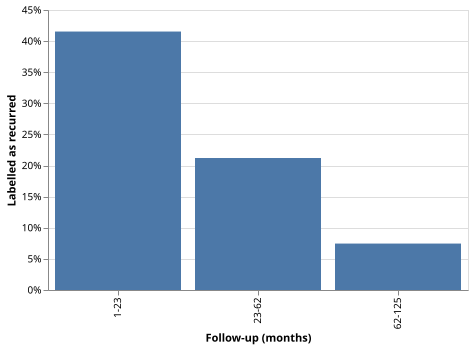

In [3]:
import altair as alt

edges = np.quantile(time, [0, 1 / 3, 2 / 3, 1.0])
terciles = []
for i in range(3):
    band = (time >= edges[i]) & (time <= edges[i + 1])
    terciles.append({
        "follow-up (months)": f"{edges[i]:.0f}-{edges[i + 1]:.0f}",
        "patients": int(band.sum()),
        "recurred": float(status[band].mean()),
    })
tercile_frame = pl.DataFrame(terciles)

alt.Chart(tercile_frame).mark_bar().encode(
    x=alt.X("follow-up (months):N", title="Follow-up (months)", sort=None),
    y=alt.Y("recurred:Q", title="Labelled as recurred", axis=alt.Axis(format="%")),
    tooltip=[alt.Tooltip("patients:Q", title="Patients"),
             alt.Tooltip("recurred:Q", format=".1%", title="Labelled as recurred")],
).properties(width=420, height=280)

The recurrence rate falls with follow-up length: 41.5% of the shortest-followed
third are labelled as recurred, against 7.5% of the longest.

Longer observation does not make recurrence less likely to occur; it makes it
more likely to be observed. The direction here is a consequence of the
recording: recurrence ends a patient's follow-up, so an early recurrence
produces a short follow-up time, and a long follow-up time indicates that
nothing was observed.

The label therefore reflects both the patient and the study design.

## Classifier on follow-up time alone

If part of the label is administrative, a purely administrative variable should
predict it. Follow-up time is a property of the observation window set by the study: it is unknown at
diagnosis and is not measured by a biopsy. Fitting a classifier on follow-up
time alone and comparing it with one on the 32 tumour measurements quantifies
how much of the classifier's performance the administrative variable accounts
for. The comparison uses AUC, the probability that a recurrence outranks a
non-recurrence in the predicted score.

In [4]:
def auc(score):
    """Probability a recurrence outranks a non-recurrence."""
    positive = score[status == 1]
    negative = score[status == 0]
    comparisons = (positive[:, None] > negative[None, :]).astype(float)
    
    ties = (positive[:, None] == negative[None, :]).astype(float)

    followup_only = mb.glmboost(
        "recurred ~ followup",
        data={"followup": time, "recurred": status.astype(float)},
        family=mb.Binomial(), control=mb.boost_control(300, 0.1),
    )

    biomarkers = mb.glmboost(
        "recurred ~ " + " + ".join(predictors),
        data={**data, "recurred": status.astype(float)},
        family=mb.Binomial(), control=mb.boost_control(200, 0.1),
    )

    print(f"AUC from follow-up time alone : {auc(np.asarray(followup_only.predict(type='response'))):.3f}")
    print(f"AUC from 32 tumour measurements: {auc(np.asarray(biomarkers.predict(type='response'))):.3f}")
    return float((comparisons + 0.5 * ties).mean())


Follow-up time alone reaches an AUC of 0.736; the 32 tumour measurements reach
0.742. The two training AUCs are similar, even though follow-up time is unavailable
at diagnosis and partly determined by recurrence itself.

The classifier's training performance therefore does not establish that it has
estimated anything about tumour biology, and nothing in that performance
separates the two contributions. A model built this way would transfer poorly
to a setting with different follow-up practices.

## Time-to-recurrence model

A time-to-recurrence model uses both the follow-up duration and recurrence
indicator. Its target is the distribution of recurrence time conditional on
tumour measurements, with censored patients contributing partial information
rather than a permanent non-recurrence label.

An accelerated failure time (AFT) model estimates it: it relates the logarithm of recurrence time linearly to the predictors, and a log-normal distribution (the logarithm of the time is normal) describes the remaining spread. A patient censored at 20 months
contributes the information that their recurrence time exceeds 20 months. A
classifier records that patient as a non-recurrer or drops them.

In [5]:
terms = " + ".join(f"bols({c})" for c in predictors)
survival = mb.gamboostLSS(
    {"mu": f"Surv(time, status) ~ {terms}", "sigma": f"Surv(time, status) ~ {terms}"},
    data=data, families=mb.LogNormalLSS(), control=mb.boost_control(150, 0.1),
)

centiles = np.asarray(survival.centiles(probs=[0.5]))
median_time = centiles[:, -1]
print(f"predicted median time to recurrence: "
      f"{median_time.min():.0f} to {median_time.max():.0f} months")

predicted median time to recurrence: 32 to 418 months


The fitted model gives a log-normal distribution for each patient's time to
recurrence. The median of that distribution serves as a prognostic score:
grouping patients into quartiles of predicted median and counting observed
recurrences within each shows how well it orders them.

In [6]:
cuts = np.quantile(median_time, [0, 0.25, 0.5, 0.75, 1.0])
rows = []
for i in range(4):
    band = (median_time >= cuts[i]) & (median_time <= cuts[i + 1])
    rows.append({
        "predicted median (months)": f"{cuts[i]:.0f}-{cuts[i + 1]:.0f}",
        "patients": int(band.sum()),
        "observed recurrences": int(status[band].sum()),
        "rate": f"{100 * status[band].mean():.1f}%",
    })
display(pl.DataFrame(rows))

predicted median (months),patients,observed recurrences,rate
str,i64,i64,str
"""32-106""",49,21,"""42.9%"""
"""106-154""",48,11,"""22.9%"""
"""154-213""",48,8,"""16.7%"""
"""213-418""",49,6,"""12.2%"""


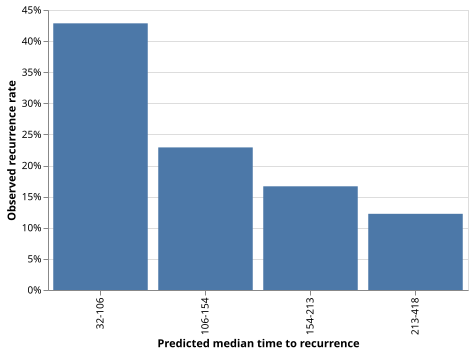

In [7]:
import altair as alt

cuts = np.quantile(median_time, [0, 0.25, 0.5, 0.75, 1.0])
quartiles = []
for i in range(4):
    band = (median_time >= cuts[i]) & (median_time <= cuts[i + 1])
    quartiles.append({
        "predicted median (months)": f"{cuts[i]:.0f}-{cuts[i + 1]:.0f}",
        "patients": int(band.sum()),
        "recurred": float(status[band].mean()),
    })
quartile_frame = pl.DataFrame(quartiles)

alt.Chart(quartile_frame).mark_bar().encode(
    x=alt.X("predicted median (months):N", title="Predicted median time to recurrence", sort=None),
    y=alt.Y("recurred:Q", title="Observed recurrence rate", axis=alt.Axis(format="%")),
    tooltip=[alt.Tooltip("patients:Q", title="Patients"),
             alt.Tooltip("recurred:Q", format=".1%", title="Observed recurrence rate")],
).properties(width=420, height=280)

The predicted median orders the patients: 43% of the shortest-predicted
quartile recurred, against 12% of the longest.

The predicted medians span 32 to 418 months. These are fitted recurrence-time
summaries, whereas the classifier's probabilities lack a common time horizon.
Using the medians to choose clinical follow-up intervals would require separate
validation of their calibration and the follow-up decision.

`plot_lss` shows the fitted structure: the partial effect of each predictor on
`mu`, the location of log-time, and on `sigma`, the scale of log-time.

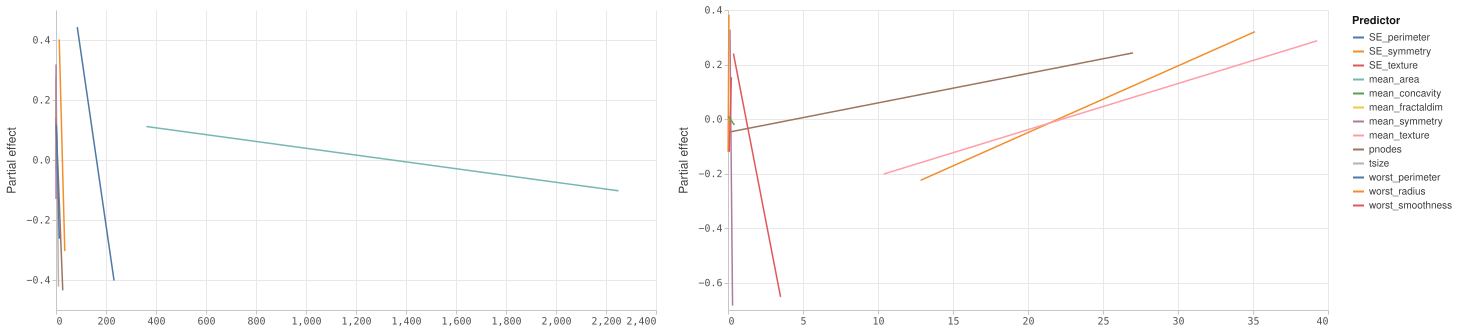

In [8]:
mb.plot.plot_lss(survival)

`plot_lss_selected` shows how often each predictor was selected for each
parameter over the 150 boosting iterations.

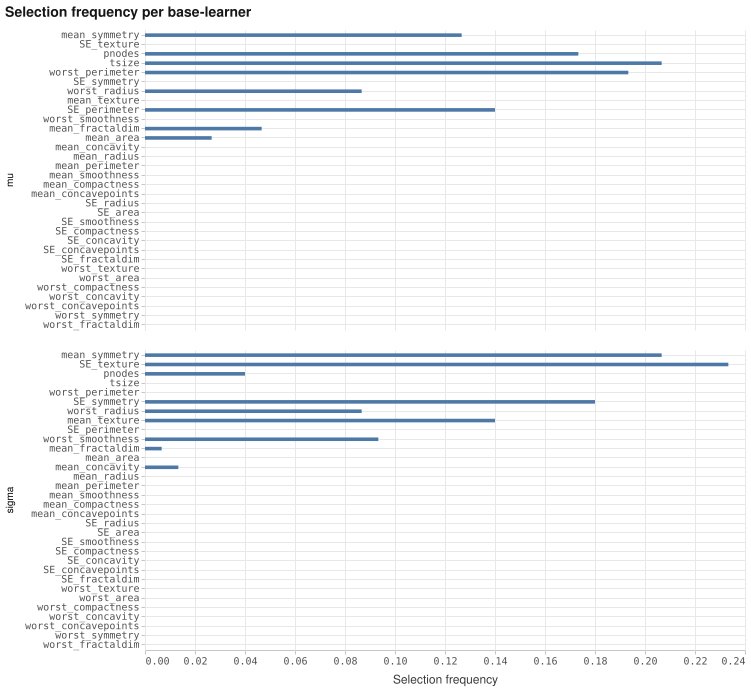

In [9]:
mb.plot.plot_lss_selected(survival)

## Conclusions

The tumour measurements carry prognostic information, and a survival model
expresses it on a time scale that does not depend on the study's follow-up
window.

Several stronger claims are not supported. The classifier ranks patients
moderately well, since risk and follow-up length are correlated and higher-risk
patients recur sooner; what cannot be determined is how much of that ranking
comes from biology and how much from observation length. The effective sample
size is the number of events, 46, rather than the 194 rows, because a censored row gives only a lower bound on recurrence time. So 32 predictors
are fitted with about one and a half events each, which places this analysis in
the regime [](after_selection.ipynb) describes. Absolute risk does not transfer
to another population, since the recurrence rate depends on treatment,
screening and referral patterns, none of which are recorded.

A censored observation is an observed lower bound — the recurrence time exceeds
20 months — and an AFT model uses that bound. A classifier converts the same
observation into a label that combines the patient with the study design. The
distinction is in the estimand: time until recurrence is a property of the
patient, while whether recurrence was recorded within a window is a property of
the data collection. Any outcome defined by a window, such as churn within 30
days or readmission within a year, carries that window in its definition.